# Feature Research

**Purpose.** Build the features, check none of them leak, and find out which (if
any) carry predictive power. Before I train anything I want to care about.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.figsize": (12, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.color": "#D9E2E4",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
pd.set_option("display.width", 170)

TEAL, AMBER, RED, GREY = "#0E7C86", "#C77700", "#C0392B", "#7A8B90"

RAW = Path("../data/01-raw")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

# From notebook 02. The maximum d* across my tickers, not the median, so no
# series is left sitting on the stationarity threshold.
D_STAR = 0.65

bars = {path.stem: pd.read_parquet(path) for path in sorted(RAW.glob("*.parquet"))}

print(f"Loaded {len(bars)} tickers")
print(f"Using fractional differencing order d = {D_STAR}")

Loaded 11 tickers
Using fractional differencing order d = 0.65


### The one rule that matters: no look-ahead

Every feature at time *t* must use only information available at time *t*. If
any feature contains even a trace of the future, the model will find it, the
results will look excellent, and none of it will be real.

Two things make this easy to get wrong in pandas:

- **Rolling windows are backward-looking by default**, which is what I want.
  `close.rolling(21).mean()` at row *t* uses rows *t−20* to *t*. Safe.
- **The target must be shifted forward, not the features backward.** My target
  is tomorrow's return, so I compute it with `.shift(-1)`. That negative shift
  is the only place in the whole notebook where future data appears, and it
  belongs only in the target.

I write the feature builder once and check it explicitly afterwards rather than
trusting that I got it right.

In [2]:
def rsi(close, window=14):
    """Wilder's RSI. Uses an exponential average, so no future data."""
    delta = close.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / window, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / window, adjust=False).mean()
    strength = gain / loss.replace(0, np.nan)

    return (100 - 100 / (1 + strength)).fillna(50)


def fracdiff_weights(d, threshold=1e-4, max_terms=10_000):
    """Weights for fractional differencing of order d."""
    weights = [1.0]

    for k in range(1, max_terms):
        weight = -weights[-1] * (d - k + 1) / k

        if abs(weight) < threshold:
            break

        weights.append(weight)

    return np.array(weights)


def fracdiff(series, d, threshold=1e-4):
    """Fixed-width fractional differencing, as derived in notebook 02."""
    weights = fracdiff_weights(d, threshold)
    width = len(weights)
    values = pd.Series(series).dropna()

    if len(values) <= width:
        return pd.Series(dtype=float)

    transformed = np.convolve(values.to_numpy(dtype=float), weights, mode="valid")

    return pd.Series(transformed, index=values.index[width - 1 :])

In [3]:
def build_features(frame, d_star=D_STAR):
    """Every feature, computed only from data available at each row."""
    close = frame["adj_close"]
    daily_return = close.pct_change()

    features = pd.DataFrame(index=frame.index)

    # Momentum over several horizons. Each is a return ending today.
    for window in [1, 2, 3, 5, 10, 21]:
        features[f"ret_{window}d"] = close.pct_change(window)

    # Distance from a moving average, as a fraction. Scale-free, so it is
    # comparable across tickers and across time.
    for window in [5, 10, 21, 63]:
        features[f"px_over_ma_{window}"] = close / close.rolling(window).mean() - 1

    # Realised volatility. Notebook 01 showed this is the most persistent thing
    # in the data, so it is the feature I expect most from.
    for window in [10, 21, 63]:
        features[f"vol_{window}d"] = daily_return.rolling(window).std()

    features["rsi_14"] = rsi(close, 14)

    # Short volatility against long. Above 1 means conditions are heating up.
    features["vol_ratio"] = features["vol_10d"] / features["vol_63d"]

    # Today's volume against its recent average.
    features["volume_ratio"] = frame["volume"] / frame["volume"].rolling(21).mean()

    # The stationary-but-memory-preserving price series from notebook 02.
    features["fracdiff"] = fracdiff(np.log(close), d_star)

    return features


def forward_return(frame, horizon=1):
    """The target: the return over the next `horizon` days.

    The negative shift is the only place future data is allowed.
    """
    return frame["adj_close"].pct_change(horizon).shift(-horizon)

### Proving there is no leak

Three checks, because this is the one mistake that would invalidate everything
downstream and it leaves no obvious trace.

**Check 1: truncation.** If I compute the features on a shortened series, the
values at every shared date must be identical. A feature that used future data
would change when the future is removed.

**Check 2: the target is genuinely ahead.** The target at row *t* must equal the
return computed between row *t* and row *t+1*, not something involving row *t*
itself.

**Check 3: no feature is suspiciously correlated with the target.** A feature
carrying leaked future information would show a correlation near 1. Real
features on daily data should show almost nothing.

In [4]:
spy = bars["SPY"]

full = build_features(spy)
truncated = build_features(spy.iloc[:-200])

shared = truncated.index
differences = (full.loc[shared] - truncated).abs().max()

print("Check 1: features recomputed on a shortened series")
print(f"  largest difference at any shared date: {differences.max():.2e}")
print(f"  passes: {differences.max() < 1e-10}")
print()

target = forward_return(spy)
manual = (spy["adj_close"].shift(-1) / spy["adj_close"] - 1)

print("Check 2: the target is tomorrow's return")
print(f"  matches a manual calculation: {np.allclose(target.dropna(), manual.dropna())}")
print(f"  last row is NaN (no tomorrow): {pd.isna(target.iloc[-1])}")

Check 1: features recomputed on a shortened series
  largest difference at any shared date: 0.00e+00
  passes: True

Check 2: the target is tomorrow's return
  matches a manual calculation: True
  last row is NaN (no tomorrow): True


### Assembling the dataset

Features and target joined, with the warm-up rows dropped. The longest window is
the fractional differencing one, which costs the most rows.

In [5]:
X = build_features(spy)
y = forward_return(spy)

data = X.join(y.rename("target")).dropna()
features, target = data[X.columns], data["target"]

print(f"Features built     : {X.shape[1]}")
print(f"Rows before dropna : {len(X):,}")
print(f"Rows usable        : {len(data):,}")
print(f"Warm-up cost       : {len(X) - len(data):,} rows")
print()
print(list(X.columns))

Features built     : 17
Rows before dropna : 5,032
Rows usable        : 4,915
Warm-up cost       : 117 rows

['ret_1d', 'ret_2d', 'ret_3d', 'ret_5d', 'ret_10d', 'ret_21d', 'px_over_ma_5', 'px_over_ma_10', 'px_over_ma_21', 'px_over_ma_63', 'vol_10d', 'vol_21d', 'vol_63d', 'rsi_14', 'vol_ratio', 'volume_ratio', 'fracdiff']


### Information Coefficient

The standard way to ask whether a feature predicts anything. The IC is the rank
correlation between a feature today and the return tomorrow.

I use rank correlation rather than ordinary correlation because it does not care
about outliers or the exact shape of the relationship, only whether high values
of the feature tend to come before high returns. On data with tails as fat as
notebook 01 showed, that matters.

**What counts as good.** In this field an IC of 0.02 to 0.05 is a real signal
worth trading. An IC of 0.1 would be exceptional. An IC of 0.5 means I have
leaked something. I should expect most of my features to come in near zero, and
that is not a failure of the features, it is what daily equity data is like.

In [7]:
rows = []

for column in features.columns:
    result = stats.spearmanr(features[column], target)
    rows.append({
        "feature": column,
        "ic": result.statistic,
        "p_value": result.pvalue,
        "abs_ic": abs(result.statistic),
    })

information = pd.DataFrame(rows).set_index("feature").sort_values("abs_ic", ascending=False)
information["significant"] = information["p_value"] < 0.05

information.round(4)

,ic,p_value,abs_ic,significant
feature,,,,
rsi_14,-0.0592,0.0000,0.0592,True
px_over_ma_10,-0.0492,0.0006,0.0492,True
ret_5d,-0.0480,0.0008,0.0480,True
px_over_ma_21,-0.0471,0.0010,0.0471,True
ret_10d,-0.0465,0.0011,0.0465,True
px_over_ma_5,-0.0423,0.0030,0.0423,True
ret_2d,-0.0419,0.0033,0.0419,True
px_over_ma_63,-0.0372,0.0092,0.0372,True
ret_1d,-0.0359,0.0119,0.0359,True


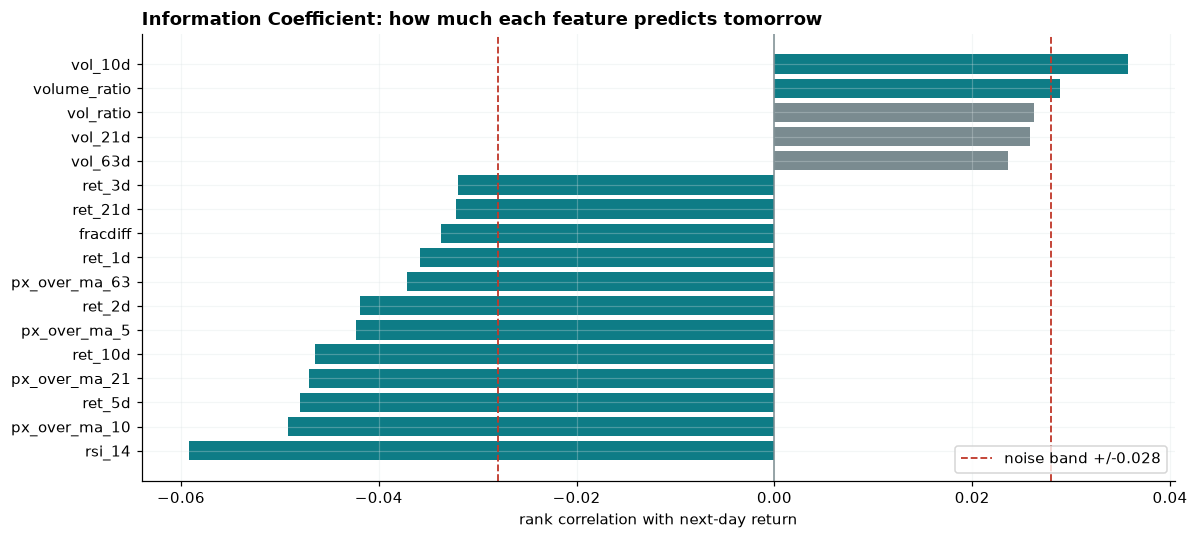

Largest absolute IC: 0.0592
Features outside the noise band: 14 of 17


In [8]:
figure, axis = plt.subplots(figsize=(11, 5))

ordered = information.sort_values("ic")
colours = [TEAL if significant else GREY for significant in ordered["significant"]]

axis.barh(ordered.index, ordered["ic"], color=colours)
axis.axvline(0, color=GREY, lw=1)

# Rough band for what random noise would produce on this sample size.
band = 1.96 / np.sqrt(len(target))
axis.axvline(band, color=RED, ls="--", lw=1.2)
axis.axvline(-band, color=RED, ls="--", lw=1.2,
             label=f"noise band +/-{band:.3f}")

axis.set_title("Information Coefficient: how much each feature predicts tomorrow",
               loc="left", fontweight="bold")
axis.set_xlabel("rank correlation with next-day return")
axis.legend(loc="lower right")

save("03_information_coefficient")
plt.show()

print(f"Largest absolute IC: {information['abs_ic'].max():.4f}")
print(f"Features outside the noise band: {int((information['abs_ic'] > band).sum())} "
      f"of {len(information)}")

## Does the signal survive in different regimes?

An IC computed over twenty years can hide a feature that worked brilliantly in
one period and not at all since. That is exactly the false discovery the paper
warns about, and it is only visible if I split the sample.

This is also the most useful thing in the notebook for building a model. A
feature with a modest IC that is **consistent** is worth more than one with a
larger IC that comes entirely from a single period.

In [9]:
regimes = {
    "2005-2007": ("2005-01-01", "2007-12-31"),
    "2008-2009": ("2008-01-01", "2009-12-31"),
    "2010-2014": ("2010-01-01", "2014-12-31"),
    "2015-2019": ("2015-01-01", "2019-12-31"),
    "2020-2024": ("2020-01-01", "2024-12-31"),
}

by_regime = {}

for name, (start, end) in regimes.items():
    window = data.loc[start:end]

    if len(window) < 100:
        continue

    by_regime[name] = {
        column: stats.spearmanr(window[column], window["target"]).statistic
        for column in features.columns
    }

regime_ic = pd.DataFrame(by_regime)
regime_ic["mean"] = regime_ic.mean(axis=1)
regime_ic["std"] = regime_ic.iloc[:, :-1].std(axis=1)

# How consistent a feature is, relative to how large its signal is.
regime_ic["consistency"] = regime_ic["mean"].abs() / regime_ic["std"]
regime_ic["same_sign"] = (regime_ic.iloc[:, : len(by_regime)] > 0).sum(axis=1)

regime_ic.sort_values("consistency", ascending=False).round(4)

,2005-2007,2008-2009,2010-2014,2015-2019,2020-2024,mean,std,consistency,same_sign
fracdiff,-0.0908,-0.0702,-0.0633,-0.0418,-0.0579,-0.0648,0.0179,3.6150,0
ret_1d,-0.0618,-0.0541,-0.0342,-0.0436,-0.0263,-0.0440,0.0144,3.0611,0
ret_10d,-0.0860,-0.0391,-0.0441,-0.0662,-0.0274,-0.0526,0.0234,2.2463,0
px_over_ma_5,-0.0787,-0.0720,-0.0217,-0.0535,-0.0312,-0.0514,0.0248,2.0731,0
px_over_ma_21,-0.1000,-0.0330,-0.0594,-0.0556,-0.0314,-0.0559,0.0278,2.0129,0
rsi_14,-0.0991,-0.0157,-0.0764,-0.0706,-0.0503,-0.0624,0.0314,1.9899,0
ret_3d,-0.0519,-0.0541,-0.0072,-0.0466,-0.0287,-0.0377,0.0198,1.9087,0
ret_5d,-0.1044,-0.0162,-0.0533,-0.0441,-0.0470,-0.0530,0.0320,1.6546,0
ret_2d,-0.0940,-0.0897,-0.0227,-0.0427,-0.0245,-0.0547,0.0348,1.5714,0
px_over_ma_10,-0.1287,-0.0412,-0.0460,-0.0516,-0.0333,-0.0602,0.0389,1.5467,0


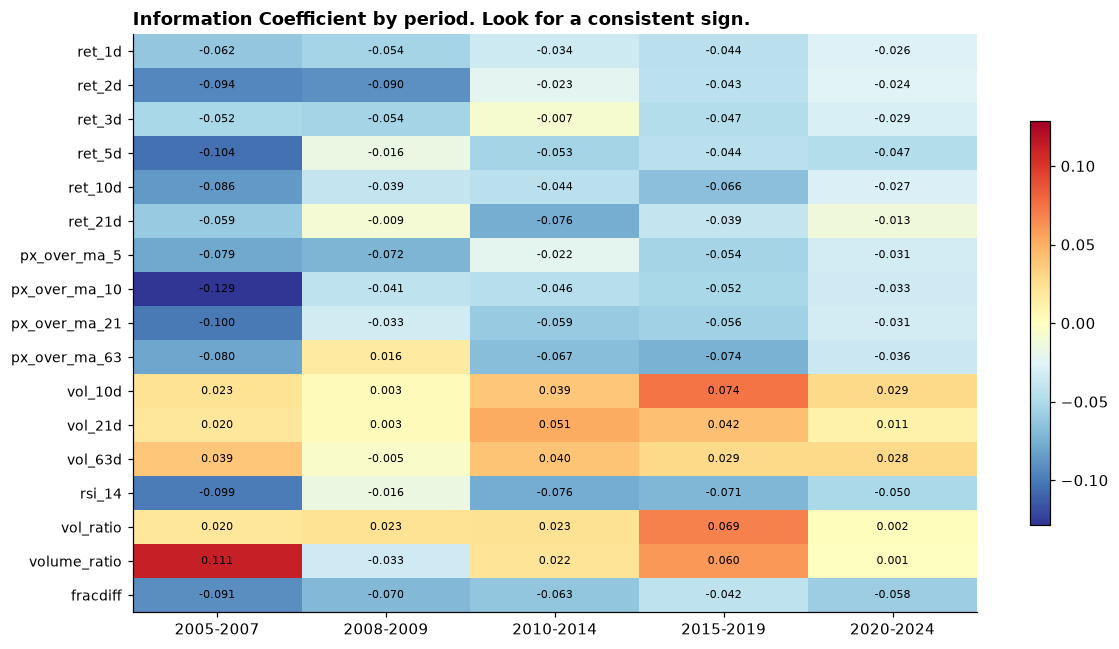

In [10]:
figure, axis = plt.subplots(figsize=(11, 6))
panel = regime_ic[list(by_regime)]
limit = panel.abs().max().max()

image = axis.imshow(panel, cmap="RdYlBu_r", aspect="auto", vmin=-limit, vmax=limit)

axis.set_xticks(range(len(panel.columns)))
axis.set_xticklabels(panel.columns, rotation=0)
axis.set_yticks(range(len(panel.index)))
axis.set_yticklabels(panel.index, fontsize=9)
axis.grid(False)

for i in range(len(panel.index)):
    for j in range(len(panel.columns)):
        axis.text(j, i, f"{panel.iloc[i, j]:.3f}", ha="center", va="center", fontsize=7.5)

figure.colorbar(image, ax=axis, shrink=0.7)
axis.set_title("Information Coefficient by period. Look for a consistent sign.",
               loc="left", fontweight="bold")

save("03_regime_stability")
plt.show()

### Which features say the same thing?

Seventeen features is not seventeen pieces of information. `ret_5d` and
`px_over_ma_5` are close to the same calculation, and the three volatility
windows will move together.

This matters for two reasons. Redundant features make tree-based importance
unreliable, because the model splits the credit between them arbitrarily. And
when I count trials for the deflated Sharpe ratio later, what matters is the
number of **independent** things I tested, not the raw count.

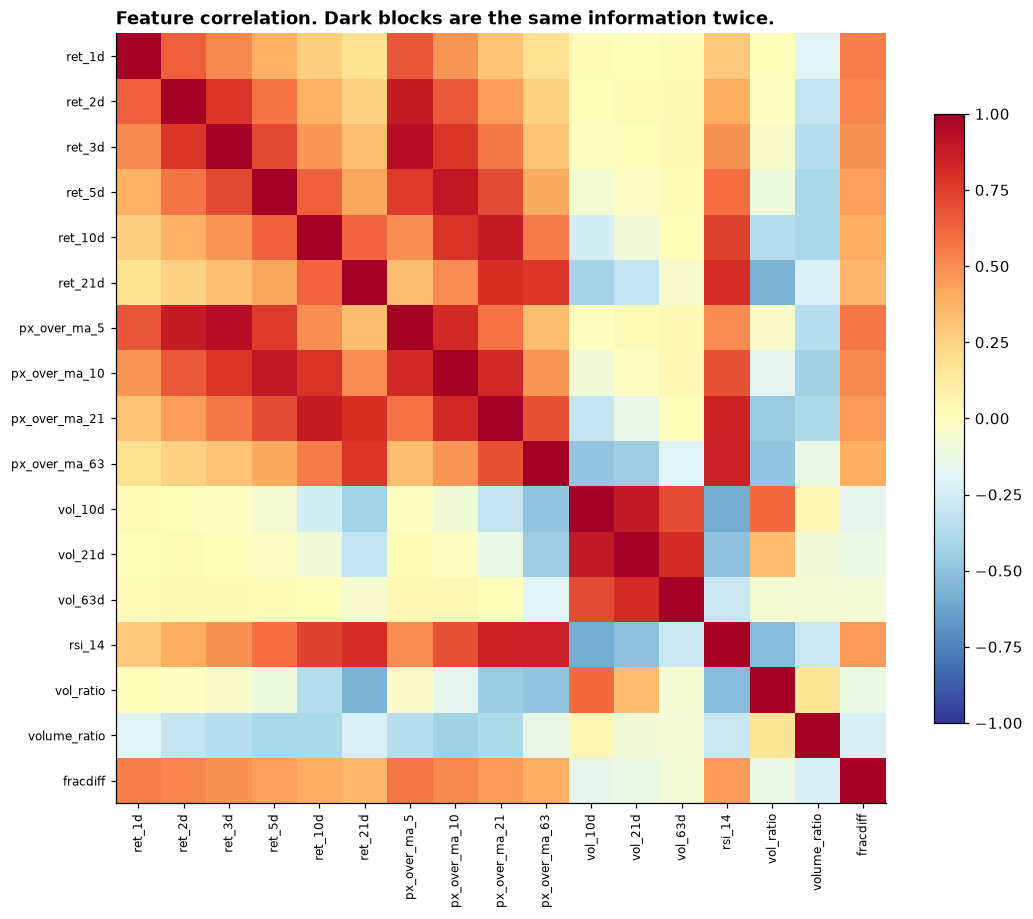

Pairs correlated above 0.9: 1
ret_3d  px_over_ma_5    0.93


In [11]:
correlation = features.corr(method="spearman")

figure, axis = plt.subplots(figsize=(10, 8.5))
image = axis.imshow(correlation, cmap="RdYlBu_r", vmin=-1, vmax=1)

axis.set_xticks(range(len(correlation)))
axis.set_yticks(range(len(correlation)))
axis.set_xticklabels(correlation.columns, rotation=90, fontsize=8)
axis.set_yticklabels(correlation.index, fontsize=8)
axis.grid(False)

figure.colorbar(image, ax=axis, shrink=0.75)
axis.set_title("Feature correlation. Dark blocks are the same information twice.",
               loc="left", fontweight="bold")

save("03_feature_correlation")
plt.show()

pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
redundant = pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False)

print(f"Pairs correlated above 0.9: {len(redundant)}")
if len(redundant):
    print(redundant.round(3).to_string())

### Purged cross-validation

Now I put the features in a model. The validation has to be right before the
result means anything.

An ordinary k-fold would be useless here. My features use rolling windows, so
the feature vector at row *t* and at row *t+1* overlap heavily. Put those two
rows in different folds and the model has effectively seen the test data. The
paper's point is sharper than that: **with overlapping data, even a completely
irrelevant feature will look predictive.**

Two protections:

- **Chronological splits.** Train always comes before test, never after.
- **An embargo.** A gap between the end of training and the start of testing,
  so the serial correlation in the features cannot carry across the boundary.
  I use 1% of the sample, which the paper says is usually enough.

My labels are next-day returns, so they do not overlap each other and full
purging is not strictly required. The embargo still is, because the **features**
overlap even when the labels do not. That distinction is worth being precise
about rather than applying machinery I do not need.

In [12]:
def purged_splits(n_rows, n_splits=5, embargo_pct=0.01, label_span=1):
    """Walk-forward splits with an embargo gap between train and test."""
    fold_size = n_rows // (n_splits + 1)
    embargo = int(n_rows * embargo_pct)

    for i in range(n_splits):
        train_end = fold_size * (i + 1)
        test_start = train_end + embargo
        test_end = min(test_start + fold_size, n_rows)

        if test_start >= n_rows:
            break

        # Drop the last label_span rows of training: their labels reach into
        # the embargo window.
        train_index = np.arange(0, max(train_end - label_span, 0))
        test_index = np.arange(test_start, test_end)

        if len(test_index) == 0:
            break

        yield train_index, test_index


splits = list(purged_splits(len(data)))

print(f"{len(splits)} folds on {len(data):,} rows\n")

for i, (train_index, test_index) in enumerate(splits, 1):
    gap = test_index[0] - train_index[-1] - 1
    print(f"  fold {i}: train {len(train_index):>5} rows, "
          f"test {len(test_index):>5} rows, embargo gap {gap} rows")

5 folds on 4,915 rows

  fold 1: train   818 rows, test   819 rows, embargo gap 50 rows
  fold 2: train  1637 rows, test   819 rows, embargo gap 50 rows
  fold 3: train  2456 rows, test   819 rows, embargo gap 50 rows
  fold 4: train  3275 rows, test   819 rows, embargo gap 50 rows
  fold 5: train  4094 rows, test   771 rows, embargo gap 50 rows


In [13]:
fold_results = []
importances = []

for i, (train_index, test_index) in enumerate(splits, 1):
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=50,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1,
    )
    model.fit(features.iloc[train_index], target.iloc[train_index])

    predicted = model.predict(features.iloc[test_index])
    actual = target.iloc[test_index]

    fold_results.append({
        "fold": i,
        "test_from": data.index[test_index[0]].date(),
        "test_to": data.index[test_index[-1]].date(),
        "ic": stats.spearmanr(predicted, actual).statistic,
        "hit_rate": float((np.sign(predicted) == np.sign(actual)).mean()),
        "always_up": float((actual > 0).mean()),
    })

    importances.append(pd.Series(model.feature_importances_, index=features.columns))

results = pd.DataFrame(fold_results)
results["edge_over_always_up"] = results["hit_rate"] - results["always_up"]

results.round(4)

,fold,test_from,test_to,ic,hit_rate,always_up,edge_over_always_up
0,1,2008-11-28,2012-02-29,0.0223,0.4908,0.5629,-0.0720
1,2,2012-03-01,2015-06-03,0.0393,0.4933,0.5580,-0.0647
2,3,2015-06-04,2018-08-31,0.0388,0.5226,0.5446,-0.0220
3,4,2018-09-04,2021-12-02,0.0279,0.5580,0.5714,-0.0134
4,5,2021-12-03,2024-12-27,0.0111,0.5214,0.5279,-0.0065


In [14]:
print(f"Mean IC across folds        : {results['ic'].mean():+.4f}")
print(f"Mean hit rate               : {results['hit_rate'].mean():.4f}")
print(f"Mean share of up days       : {results['always_up'].mean():.4f}")
print(f"Mean edge over always-up    : {results['edge_over_always_up'].mean():+.4f}")
print(f"Folds with a positive edge  : {int((results['edge_over_always_up'] > 0).sum())} "
      f"of {len(results)}")
print()
print(f"Standard deviation of IC    : {results['ic'].std():.4f}")
print("A mean near zero with a large spread means the folds disagree,")
print("which is what noise looks like.")

Mean IC across folds        : +0.0279
Mean hit rate               : 0.5172
Mean share of up days       : 0.5530
Mean edge over always-up    : -0.0357
Folds with a positive edge  : 0 of 5

Standard deviation of IC    : 0.0119
A mean near zero with a large spread means the folds disagree,
which is what noise looks like.


### Feature importance, and whether it is stable

The paper's recommended research tool. Not "what did the model score" but "what
did the model find useful, and did it keep finding the same thing".

A feature that ranks first in one fold and last in the next has not been
discovered, it has been fitted. I care more about the spread across folds than
about the average.

In [15]:
importance = pd.concat(importances, axis=1)
importance.columns = [f"fold_{i}" for i in range(1, len(importances) + 1)]

importance["mean"] = importance.mean(axis=1)
importance["std"] = importance.iloc[:, :-1].std(axis=1)

# Low spread relative to the mean means the model kept finding the same thing.
importance["stability"] = importance["mean"] / importance["std"].replace(0, np.nan)

importance.sort_values("mean", ascending=False).round(4)

,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std,stability
vol_10d,0.0680,0.0807,0.0831,0.0857,0.0961,0.0827,0.0101,8.1595
px_over_ma_5,0.0700,0.0765,0.0759,0.0747,0.0655,0.0725,0.0047,15.5278
vol_21d,0.0659,0.0656,0.0827,0.0778,0.0643,0.0713,0.0084,8.4754
fracdiff,0.1092,0.0731,0.0554,0.0523,0.0535,0.0687,0.0242,2.8411
ret_3d,0.0699,0.0573,0.0650,0.0721,0.0743,0.0677,0.0068,10.0030
ret_2d,0.0681,0.0605,0.0708,0.0697,0.0668,0.0672,0.0040,16.7580
px_over_ma_63,0.0816,0.0577,0.0748,0.0627,0.0523,0.0658,0.0121,5.4388
ret_10d,0.0266,0.0787,0.0701,0.0717,0.0669,0.0628,0.0207,3.0323
ret_21d,0.0488,0.0706,0.0613,0.0615,0.0598,0.0604,0.0078,7.7771
vol_63d,0.0605,0.0573,0.0700,0.0647,0.0439,0.0593,0.0098,6.0338


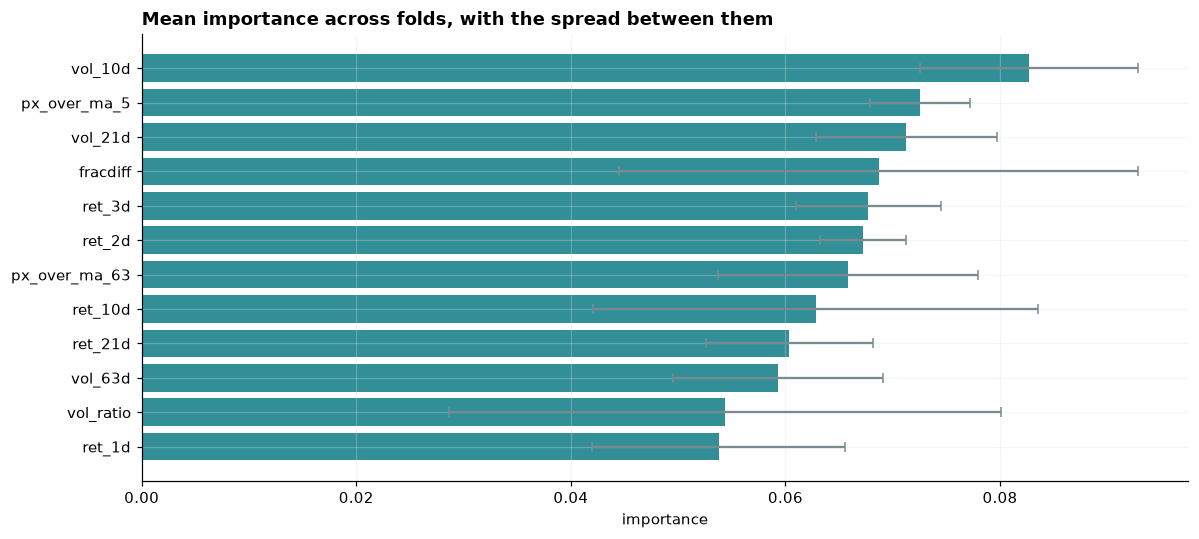

In [16]:
top = importance.sort_values("mean", ascending=False).head(12)

figure, axis = plt.subplots(figsize=(11, 5))
axis.barh(top.index[::-1], top["mean"][::-1], xerr=top["std"][::-1],
          color=TEAL, alpha=0.85, error_kw={"ecolor": GREY, "capsize": 3})

axis.set_title("Mean importance across folds, with the spread between them",
               loc="left", fontweight="bold")
axis.set_xlabel("importance")

save("03_feature_importance")
plt.show()

### The comparison that keeps me honest

Notebook 01 established the bar: 55% of days are positive, so "always buy" is
right 55% of the time while knowing nothing.

Three reference points, scored exactly the same way as the model:

- **Always up.** Predict a rise every day.
- **Random.** Predict a sign at random.
- **Yesterday's move, reversed.** Notebook 01 found lag-1 autocorrelation of
  about −0.10, which is short-horizon mean reversion. This turns that single
  observation into a rule.

If the model cannot beat all three, then whatever it learned is not worth the
complexity it cost.

In [17]:
rng = np.random.default_rng(42)
baselines = []

for i, (_, test_index) in enumerate(splits, 1):
    actual = target.iloc[test_index]
    yesterday = features.iloc[test_index]["ret_1d"]

    baselines.append({
        "fold": i,
        "always_up": float((actual > 0).mean()),
        "random": float((np.sign(rng.normal(size=len(actual))) == np.sign(actual)).mean()),
        "reverse_yesterday": float((np.sign(-yesterday) == np.sign(actual)).mean()),
        "model": results.loc[i - 1, "hit_rate"],
    })

comparison = pd.DataFrame(baselines).set_index("fold")
comparison.loc["mean"] = comparison.mean()

comparison.round(4)

,always_up,random,reverse_yesterday,model
fold,,,,
1,0.5629,0.4896,0.4896,0.4908
2,0.5580,0.4640,0.4994,0.4933
3,0.5446,0.5189,0.5336,0.5226
4,0.5714,0.5079,0.4957,0.5580
5,0.5279,0.4708,0.4838,0.5214
mean,0.5530,0.4903,0.5004,0.5172


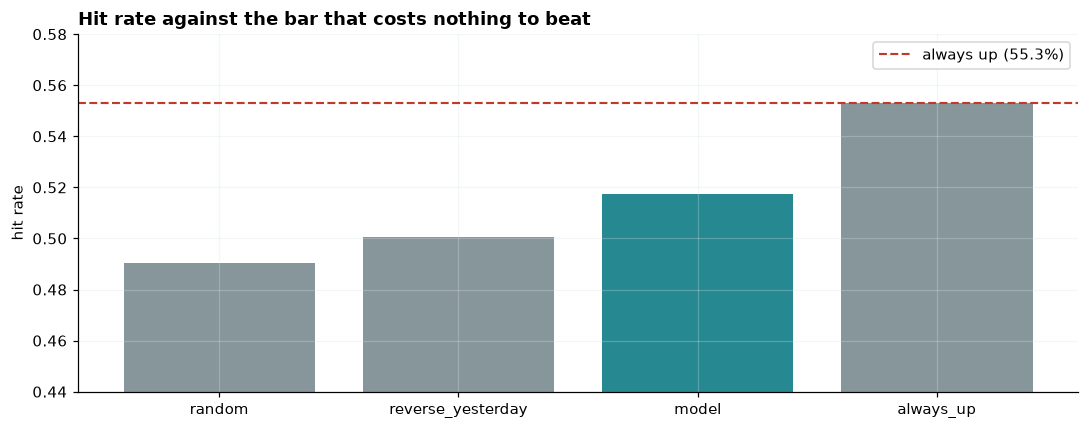

In [18]:
means = comparison.loc["mean"].sort_values()

figure, axis = plt.subplots(figsize=(10, 4))
colours = [TEAL if name == "model" else GREY for name in means.index]

axis.bar(means.index, means.to_numpy(), color=colours, alpha=0.9)
axis.axhline(comparison.loc["mean", "always_up"], color=RED, ls="--", lw=1.4,
             label=f"always up ({comparison.loc['mean', 'always_up']:.1%})")
axis.set_ylim(0.44, max(0.58, means.max() + 0.02))
axis.set_title("Hit rate against the bar that costs nothing to beat",
               loc="left", fontweight="bold")
axis.set_ylabel("hit rate")
axis.legend()

save("03_baselines")
plt.show()

### Counting the trials

Everything in this notebook is a trial, and the deflated Sharpe ratio later will
need the count. I cannot reconstruct it afterwards, so I record it now.

Being honest here is uncomfortable, because the number is larger than it feels
while working. Every feature tested, every model configuration, every regime
split is a chance to find something by accident.

In [19]:
trials = {
    "features tested individually": len(features.columns),
    "regime splits examined": len(by_regime),
    "model configurations tried": 1,
    "cross-validation folds": len(splits),
}

for name, count in trials.items():
    print(f"{name:32s} {count}")

print()
print(f"Features correlated above 0.9 : {len(redundant)}")

# Correlated features are not independent tests, so the effective count is
# lower than the raw one.
effective = len(features.columns) - len(redundant)
print(f"Roughly independent features   : {effective}")
print()
print("These go in the trial log before any backtest is run.")

features tested individually     17
regime splits examined           5
model configurations tried       1
cross-validation folds           5

Features correlated above 0.9 : 1
Roughly independent features   : 16

These go in the trial log before any backtest is run.
